# K-Means Customer Segmentation

Train a K-Means model on customer-level purchase behavior. The supplied workbook is the available training dataset; no separate train/test files or labels are provided.

# Imports and Data Cleaning

## Import dependencies

In [43]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
)
from sklearn.preprocessing import MinMaxScaler
from yellowbrick.cluster import KElbowVisualizer

sns.set_theme(style="whitegrid", palette="Set2")
RANDOM_STATE = 42

## Load the training dataset

In [44]:
data_path = Path("../data/Online Retail.xlsx")
raw_data = pd.read_excel(data_path)

print(f"Raw rows: {len(raw_data):,}")
print(f"Raw columns: {raw_data.columns.tolist()}")
raw_data.head()

Raw rows: 541,909
Raw columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## Clean transactions

In [45]:
# Parse identifiers and dates before filtering.
transactions = raw_data.copy()

# Remove invalid invoices
transactions = transactions[((transactions['InvoiceNo'].str[0] == 'C') == False) & ((transactions['InvoiceNo'].str[0] == 'A') == False)]

# Remove quantity and price less than or equal to zero
transactions = transactions[(transactions['Quantity'] > 0) & (transactions['UnitPrice'] > 0)]

# Remove null customers
transactions = transactions[transactions['CustomerID'].notnull()]

# Cast CustomerID to integer
transactions['CustomerID'] = transactions['CustomerID'].astype(int)

print(f"Rows after cleaning: {len(transactions):,}")
print(f"Identified customers: {transactions['CustomerID'].nunique():,}")
print(f"Date range: {transactions['InvoiceDate'].min()} to {transactions['InvoiceDate'].max()}")

Rows after cleaning: 397,884
Identified customers: 4,338
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


# Feature Engineering

## Reference date and recency

In [46]:
# Use the latest valid invoice date in the training data as the reference date.
reference_date = transactions["InvoiceDate"].max()

recency = (
    transactions.groupby("CustomerID")["InvoiceDate"]
    .max()
    .rsub(reference_date)
    .dt.total_seconds()
    .div(24 * 60 * 60)
    .rename("RecencyDays")
    .reset_index()
)

recency.head()

,CustomerID,RecencyDays
0,12346,325.117361
1,12347,1.873611
2,12348,74.984028
3,12349,18.124306
4,12350,309.867361


## Frequency (distinct valid invoices)

In [47]:
# Count distinct valid purchase invoices for each customer.
frequency = (
    transactions.groupby("CustomerID", as_index=False)["InvoiceNo"]
    .nunique()
    .rename(columns={"InvoiceNo": "Frequency"})
)

frequency.head()

,CustomerID,Frequency
0,12346,1
1,12347,7
2,12348,4
3,12349,1
4,12350,1


## Monetary value

In [48]:
# Monetary value is the customer's total valid spend in the dataset.
transactions["LineSpend"] = transactions["Quantity"] * transactions["UnitPrice"]

monetary = (
    transactions.groupby("CustomerID", as_index=False)["LineSpend"]
    .sum()
    .rename(columns={"LineSpend": "Monetary"})
)

monetary.head()

,CustomerID,Monetary
0,12346,77183.60
1,12347,4310.00
2,12348,1797.24
3,12349,1757.55
4,12350,334.40


## Merge customer features

In [49]:
customer_features = (
    recency
    .merge(frequency, on="CustomerID", how="inner")
    .merge(monetary, on="CustomerID", how="inner")
)

# Every customer in the cleaned transaction data has at least one valid invoice.
model_customers = customer_features.copy()
feature_columns = ["RecencyDays", "Frequency", "Monetary"]

print(f"Customers included in K-Means: {len(model_customers):,}")
display(model_customers[feature_columns].describe().T)

Customers included in K-Means: 4,338


,count,mean,std,min,25%,50%,75%,max
RecencyDays,4338.0,92.049317,100.013298,0.00,17.072396,50.089931,141.730556,373.122917
Frequency,4338.0,4.272015,7.697998,1.00,1.000000,2.000000,5.000000,209.000000
Monetary,4338.0,2054.266460,8989.230441,3.75,307.415000,674.485000,1661.740000,280206.020000


# Model Training and Inference

## Transform features

In [50]:
# These features are non-negative after transaction cleaning.
X_log = np.log1p(model_customers[feature_columns])

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X_log)

print(f"Training matrix shape: {X_scaled.shape}")
print("Scaled feature minima:", X_scaled.min(axis=0))
print("Scaled feature maxima:", X_scaled.max(axis=0))

Training matrix shape: (4338, 3)
Scaled feature minima: [0. 0. 0.]
Scaled feature maxima: [1. 1. 1.]


## Select k with Yellowbrick

The Yellowbrick elbow visualizer compares within-cluster distortion over candidate k values. If it cannot locate a clear elbow, use the candidate with the highest silhouette score as a documented fallback.

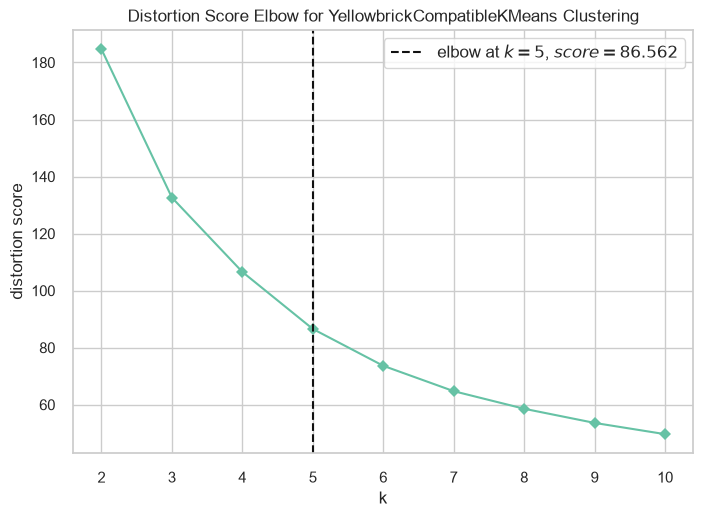

Yellowbrick selected k=5


In [51]:
# Yellowbrick 1.5 checks the legacy estimator type attribute.
# This subclass keeps that check compatible with newer scikit-learn releases.
class YellowbrickCompatibleKMeans(KMeans):
    _estimator_type = "clusterer"

elbow_model = YellowbrickCompatibleKMeans(
    init="k-means++",
    n_init=20,
    random_state=RANDOM_STATE,
)

visualizer = KElbowVisualizer(
    elbow_model,
    k=(2, 11),
    metric="distortion",
    timings=False,
    locate_elbow=True,
)
visualizer.fit(X_scaled)
visualizer.show()

optimal_k = visualizer.elbow_value_

if optimal_k is None:
    candidate_scores = {}
    for candidate_k in range(2, 11):
        candidate_model = KMeans(
            n_clusters=candidate_k,
            init="k-means++",
            n_init=20,
            random_state=RANDOM_STATE,
        )
        candidate_labels = candidate_model.fit_predict(X_scaled)
        candidate_scores[candidate_k] = silhouette_score(X_scaled, candidate_labels)

    optimal_k = max(candidate_scores, key=candidate_scores.get)
    print(f"No elbow was detected; using the highest silhouette candidate: k={optimal_k}")
else:
    print(f"Yellowbrick selected k={optimal_k}")

## Train K-Means and assign clusters

In [52]:
kmeans = KMeans(
    n_clusters=optimal_k,
    init="k-means++",
    n_init=20,
    random_state=RANDOM_STATE,
)

kmeans.fit(X_scaled)
cluster_labels = kmeans.predict(X_scaled)

clustered_customers = model_customers.copy()
clustered_customers["Cluster"] = cluster_labels

print(f"Fitted model with k={optimal_k}")
display(clustered_customers[["CustomerID", "Cluster"]].head())

Fitted model with k=5


,CustomerID,Cluster
0,12346,1
1,12347,2
2,12348,3
3,12349,0
4,12350,1


## Evaluate clustering metrics

Silhouette is better when higher; Davies–Bouldin is better when lower; Calinski–Harabasz is better when higher. These internal metrics complement business interpretability and do not establish that segments are useful by themselves.

In [53]:
evaluation = pd.Series({
    "Silhouette score": silhouette_score(X_scaled, cluster_labels),
    "Davies-Bouldin score": davies_bouldin_score(X_scaled, cluster_labels),
    "Calinski-Harabasz score": calinski_harabasz_score(X_scaled, cluster_labels),
}, name="Score")

display(evaluation.to_frame())

,Score
Silhouette score,0.352656
Davies-Bouldin score,0.963412
Calinski-Harabasz score,3756.881287


# Cluster Visualization

## Cluster feature means and sizes

In [54]:
cluster_profiles = (
    clustered_customers.groupby("Cluster")
    .agg(
        CustomerCount=("CustomerID", "nunique"),
        MeanRecencyDays=("RecencyDays", "mean"),
        MeanFrequency=("Frequency", "mean"),
        MeanMonetary=("Monetary", "mean"),
    )
    .sort_index()
)

display(cluster_profiles.round(2).reset_index())

,Cluster,CustomerCount,MeanRecencyDays,MeanFrequency,MeanMonetary
0,0,1078,49.98,1.57,483.76
1,1,1287,225.26,1.53,526.44
2,2,436,6.09,17.30,10858.15
3,3,951,50.56,5.68,2481.17
4,4,586,8.18,3.28,1055.70


## PCA scatter plot

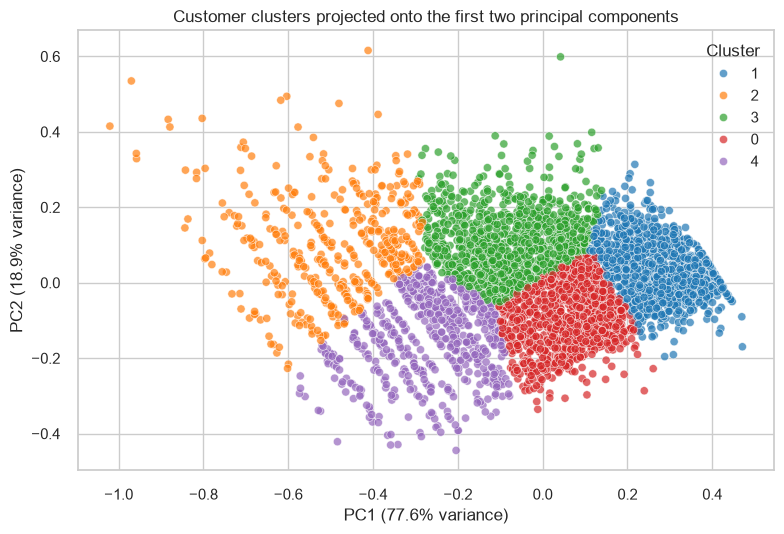

Variance explained by the two components: 96.6%


In [55]:
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

pca_plot = pd.DataFrame({
    "PC1": principal_components[:, 0],
    "PC2": principal_components[:, 1],
    "Cluster": cluster_labels.astype(str),
})

sns.scatterplot(
    data=pca_plot,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    alpha=0.7,
    s=35,
)
plt.title("Customer clusters projected onto the first two principal components")
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%} variance)")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%} variance)")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print(f"Variance explained by the two components: {pca.explained_variance_ratio_.sum():.1%}")

## 3D scatter plot

Plot customers in the three scaled feature dimensions used by K-Means. Colors indicate the assigned cluster.

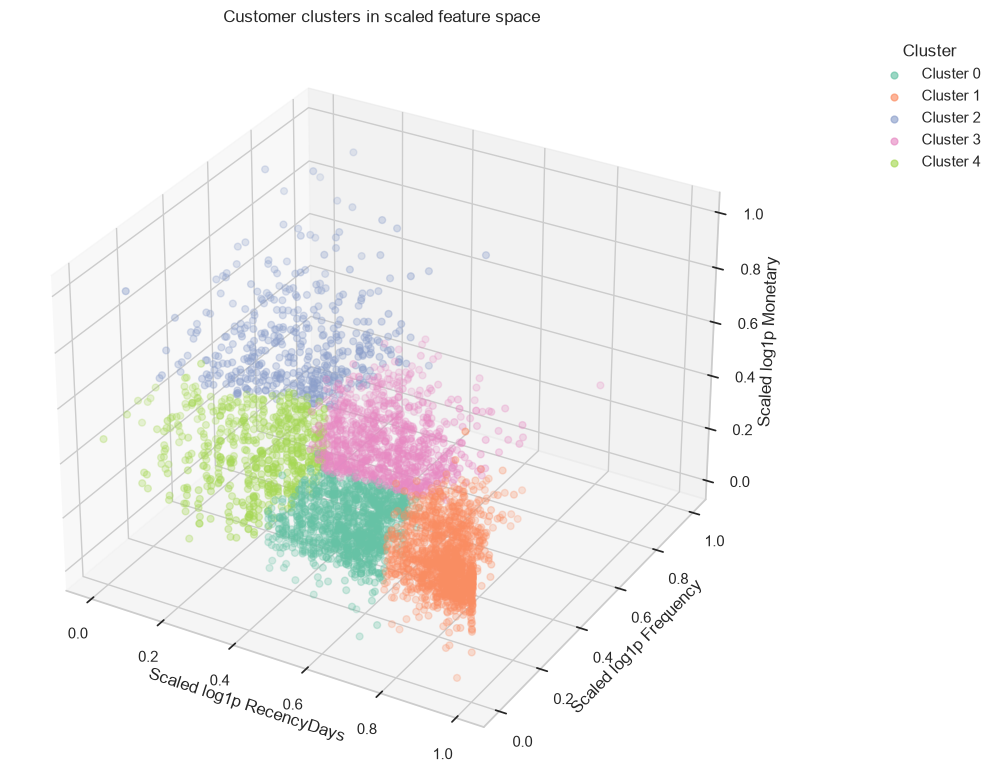

In [56]:
fig = plt.figure(figsize=(11, 8))
ax = fig.add_subplot(111, projection="3d")

for cluster_id in sorted(np.unique(cluster_labels)):
    mask = cluster_labels == cluster_id
    ax.scatter(
        X_scaled[mask, 0],
        X_scaled[mask, 1],
        X_scaled[mask, 2],
        label=f"Cluster {cluster_id}",
        alpha=0.65,
        s=24,
    )

ax.set_title("Customer clusters in scaled feature space")
ax.set_xlabel("Scaled log1p RecencyDays")
ax.set_ylabel("Scaled log1p Frequency")
ax.set_zlabel("Scaled log1p Monetary")
ax.legend(title="Cluster", bbox_to_anchor=(1.15, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Interpretation Notes

- Cluster 0: at risk (high recency) customers that used to buy rarely and generate lower revenue<br />
- Cluster 1: lost/low value customers. Average last purchase was a long time ago and average revenue is low.<br />
- Cluster 2: top customers: good recency, frequency and excellent revenue.<br />
- Cluster 3: at risk (high recency) customers that used to buy often and generate high revenue.<br />
- Cluster 4: loyal customers. Not so high revenue, but good frequency and recency.<br />